In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("alunos_senai_sig.csv")
print(df.head())

             Nome   Curso  Media_Final
0     Diego Souza  Python          5.9
1    Aline Soares  Python          4.7
2  Rafael Martins  Python          6.1
3  Thiago Almeida  Python          9.4
4   Julia Ribeiro  Python          5.6


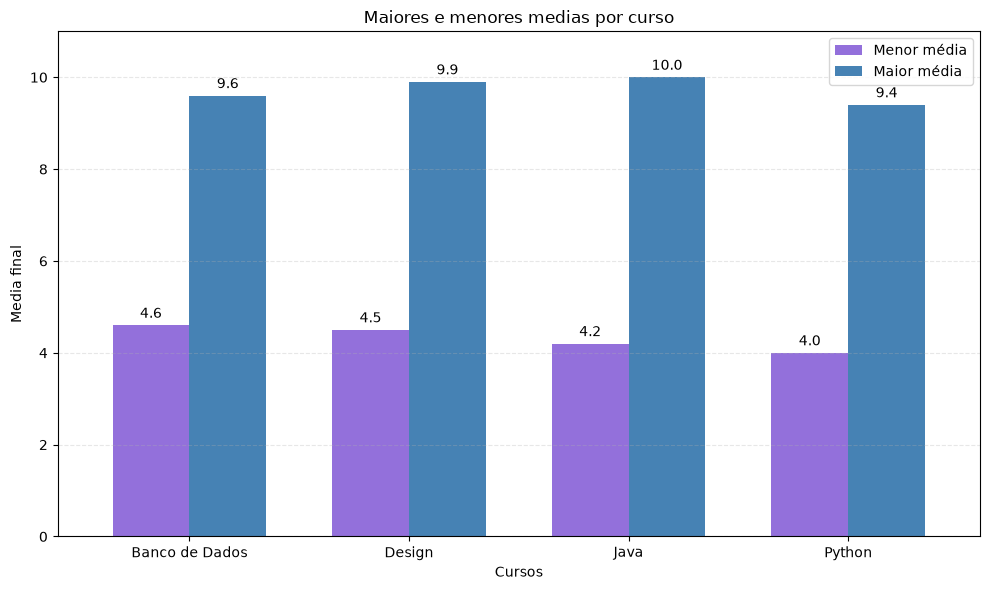

In [15]:
medias = df.groupby("Curso")["Media_Final"].agg(["min", "max"])

ax = medias.plot(
    kind="bar",
    figsize=(10, 6),
    color=["mediumpurple", "steelblue"],
    width=0.7,
)

plt.title("Maiores e menores medias por curso")
plt.xlabel("Cursos")
plt.ylabel("Media final")
plt.xticks(rotation=0)
plt.ylim(0, 11)
plt.legend(["Menor média", "Maior média"])
plt.grid(axis="y", linestyle="--", alpha=0.3)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f", padding=3)

plt.tight_layout()

plt.savefig("grafico_1_medias.png", dpi=300)
plt.show()

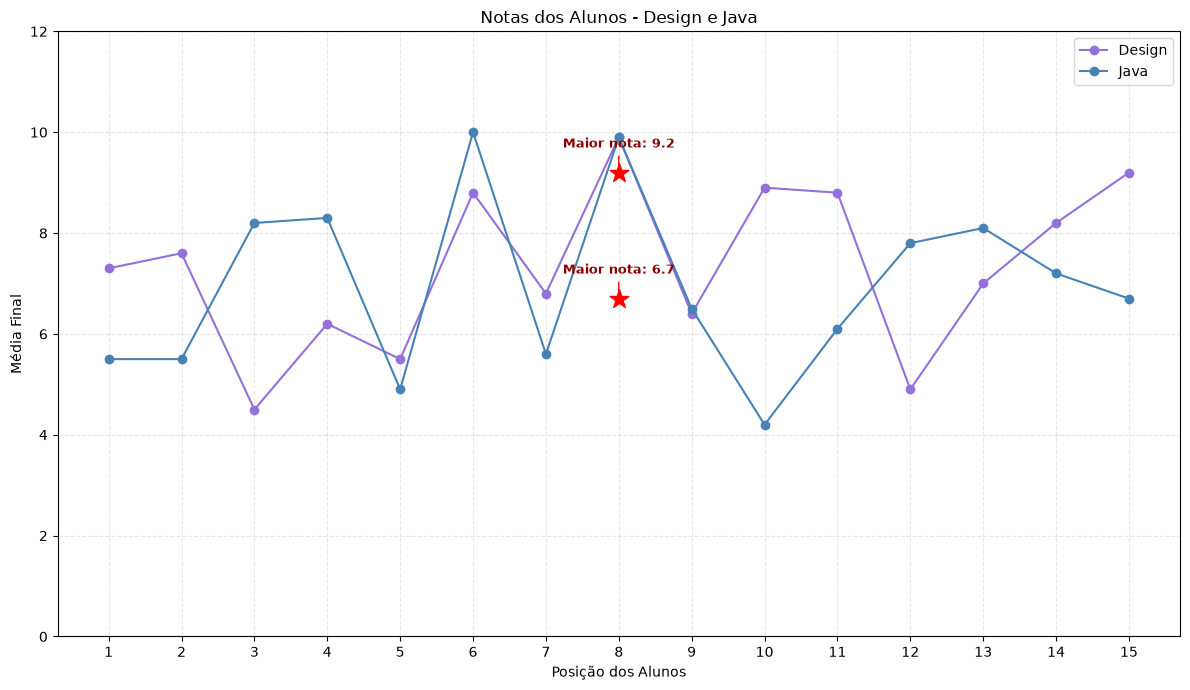

In [16]:
design = df[df["Curso"] == "Design"].reset_index(drop=True)
java = df[df["Curso"] == "Java"].reset_index(drop=True)

plt.figure(figsize=(12, 7))

plt.plot(
    range(1, len(design) + 1),
    design["Media_Final"],
    marker="o",
    color="mediumpurple",
    label="Design"
)

plt.plot(
    range(1, len(java) + 1),
    java["Media_Final"],
    marker="o",
    color="steelblue",
    label="Java"
)

dados = df[df["Curso"].isin(["Design", "Java"])]

maiores_notas = sorted(
    dados["Media_Final"].unique(),
    reverse=True
)[:2]

for curso, alunos in [("Design", design), ("Java", java)]:
    for i, aluno in alunos.iterrows():
        nota = aluno["Media_Final"]

        if nota in maiores_notas:
            x = i + 1

    plt.scatter(
        x, nota,
        color="red",
        marker="*",
        s=200,
        zorder=5
    )

    plt.annotate(
        f"Maior nota: {nota:.1f}",
        xy=(x, nota),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="darkred",
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-",
            color="red"
        )
    )

plt.title("Notas dos Alunos - Design e Java")
plt.xlabel("Posição dos Alunos")
plt.ylabel("Média Final")
plt.xticks(range(1, 16))
plt.ylim(0, 12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig("grafico_2_design_java.png", dpi=300)
plt.show()

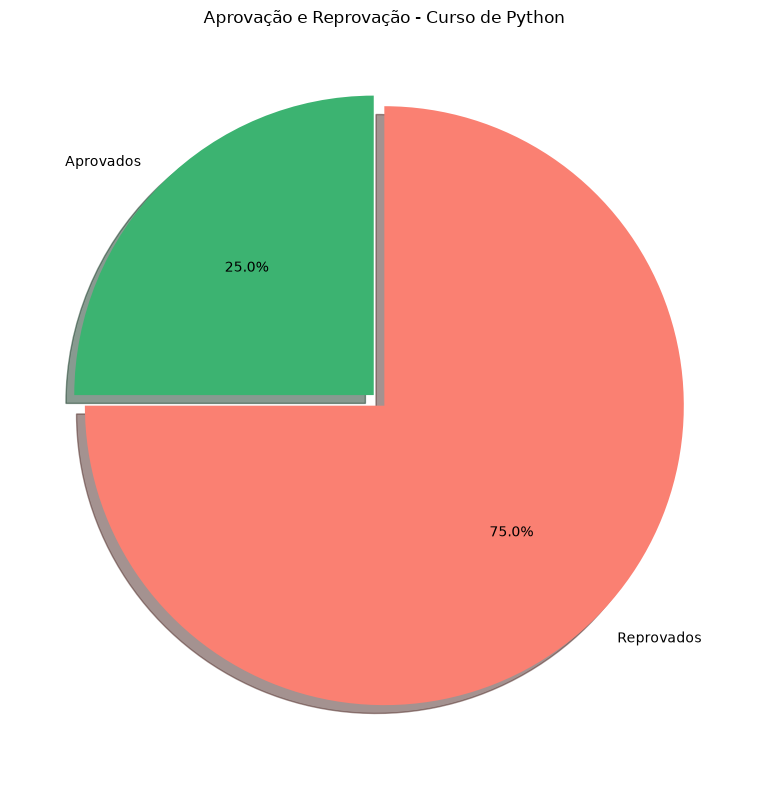

In [17]:
python = df[df["Curso"] == "Python"]

aprovados = (python["Media_Final"] >= 7).sum()
reprovados = (python["Media_Final"] < 7).sum()

plt.figure(figsize=(8, 8))

plt.pie(
    [aprovados, reprovados],
    labels=["Aprovados", "Reprovados"],
    colors=["mediumseagreen", "salmon"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.05, 0),
    shadow=True
)

plt.title("Aprovação e Reprovação - Curso de Python")

plt.tight_layout()

plt.savefig("grafico_3_python.png", dpi=300)
plt.show()
